## Midterm Project
- (a) data exploration & EDA 
- (b) Data Preprocessing and Cleaning
- (c) perform training on different models

In [37]:
import subprocess
gpu = subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout if subprocess.run(['which','nvidia-smi'], capture_output=True).returncode == 0 else ''
print(gpu or 'No Gpu detected: switch the runtime to Gpu before the SVM section training')

Thu Nov  5 10:10:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.71.09              KMD Version: 615.71.09     CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4070 ...    Off |   00000000:01:00.0 Off |                  N/A |
| N/A   38C    P8              6W /   40W |      12MiB /   8188MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

======================================================================================================
### Download the Dataset
======================================================================================================

In [38]:
# # Only execute once to download dataset
# import subprocess, zipfile
# from pathlib import Path
# DATA_DIR = Path("home-credit-default-risk")
# data_url = (
# "https://www.dropbox.com/scl/fi/86yxnx1e956jztoh5dead/"
# "home-credit-default-risk.zip?rlkey=ezc1chvbo4hw41it6unt20sb2&st=cebvj3ln&dl=1"
# )
# # Download the dataset zip with wget, then extract it into DATA_DIR
# subprocess.run(["wget", "-O", "home-credit-default-risk.zip", data_url], check=True)
# with zipfile.ZipFile("home-credit-default-risk.zip") as archive:
#  archive.extractall(DATA_DIR)

In [1]:
import os, gc, re, time, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',200)
pd.set_option('display.width',200)
sns.set_theme(style='whitegrid', context = 'notebook')
SEED = 42
np.random.seed(SEED)
DATA_DIR = 'home-credit-default-risk' # raw kaggle csvs file location
OUT_DIR = 'home-credit-default-risk/processed' # model-ready arrays written at the end and save to here
os.makedirs(DATA_DIR,exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
blue = '#4C72B0'
orange = '#DD8500'
green = '#55A868'
red = '#C44E52'
#plt.rcParams['axes.grid'] = False
CONFIG = {
    'seed': 42,
    'data_dir': 'home-credit-default-risk',   # relative path: works on Colab and Kaggle
    'out_dir': 'processed',
    'val_size': 0.20,                         # stratified train/validation split
    'days_placeholder': 365243,               # dataset's code for "not applicable" in DAYS_* columns
    'rare_category_share': 0.01,              # aux-table categories rarer than this -> 'Other'
    'recent_months': 12,                      # window for "recent" monthly-balance behaviour
    'recent_days': 365,                       # window for "recent" instalment behaviour
    'prep': dict(max_missing=0.80, max_mode_share=0.995, indicator_min_missing=0.05,
                 clip_q=(0.001, 0.999), skew_threshold=2.0, corr_threshold=0.98, min_cat_freq=0.005),
}
DAYS_PLACEHOLDER = CONFIG['days_placeholder']

### explanation of imported packages
- os Manage file paths and directories
- gc Garbage collection; helps release unused memory
- re Regular expressions for text processing
- time Measure code execution time
- warnings Control warning messages
- numpy(np) Numerical computation and arrays
- pandas (np) Load, clean, and manimulpate tabular data
- seaborn (sns) Statistical data visualization
- train_test_split Split data into training and test sets
- OneHotEncoder Convert categorical features into numerical columns
- StandardScalar Standardize numercial features

======================================================================================================
### Data Exploration & Exploratory Data Analysis (EDA)
#### Structure and data types

In [40]:
def load(name, cat=False, **kw):
    """ArithmeticError
    1. read a csv and shrink memory: float64 -> float32, int64 -> int32 (all IDs < 2^31)
    2. optional strings -> category (used for the large auxiliary tables)
    3. **kw means allows a function to accept any number of named keyword arguments
    4. convert float64 -> float32 to save memory
    """
    df = pd.read_csv(f'{DATA_DIR}/{name}.csv', **kw)
    for c in df.columns:
        t = df[c].dtype
        if t == 'float64':
            df[c] = df[c].astype('float32')
        elif t == 'int64':
            df[c] = df[c].astype('int32')
        elif cat and not pd.api.types.is_numeric_dtype(t):
            df[c] = df[c].astype('category')
    return df
def mem(df):
    #total memory usage for the dataset
    return f'{df.memory_usage(deep=True).sum() / 1e6:,.0f} MB'

======================================================================================================
#### A.1. Structure and data types
======================================================================================================

In [41]:
"""
assert check that TARGET is the only column present in app_train but not app_test 
app_test is reserved for kaggle score 
"""

app_train = load('application_train')
app_test = load('application_test')

print('application_train: ', app_train.shape, mem(app_train))
print('application_test: ', app_test.shape, mem(app_test))

assert set(app_train.columns) - set(app_test.columns) == {'TARGET'}
assert app_train.SK_ID_CURR.is_unique and app_test.SK_ID_CURR.is_unique

num_cols_raw = app_train.select_dtypes('number').columns.drop(['SK_ID_CURR','TARGET']).tolist()
cat_cols_raw = app_train.select_dtypes(exclude='number').columns.tolist()
flag_cols = [c for c in num_cols_raw if app_train[c].dropna().isin([0,1]).all()]
print(f'{len(num_cols_raw)} numeric columns ({len(flag_cols)} of them are 0/1 flags, {len(cat_cols_raw)} categorical columns)')
display(app_train.head(10)) # present first 10 rows
display(app_train[cat_cols_raw].nunique().sort_values(ascending=False).to_frame('n_levels').T)


application_train:  (307511, 122) 399 MB
application_test:  (48744, 121) 63 MB
104 numeric columns (32 of them are 0/1 flags, 16 categorical columns)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

,ORGANIZATION_TYPE,OCCUPATION_TYPE,NAME_INCOME_TYPE,NAME_TYPE_SUITE,WALLSMATERIAL_MODE,WEEKDAY_APPR_PROCESS_START,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,CODE_GENDER,FLAG_OWN_CAR,NAME_CONTRACT_TYPE,FLAG_OWN_REALTY,EMERGENCYSTATE_MODE
n_levels,58,18,8,7,7,7,6,6,5,4,3,3,2,2,2,2


#### A.2.Target Balance
- evaluate 0/1 categorical values ratio in application_train dataset

         count   share
TARGET                
0       282686  0.9193
1        24825  0.0807
Accuracy of always redicting 'repaid':0.919
Imbalance ratio: 11.4 : 1


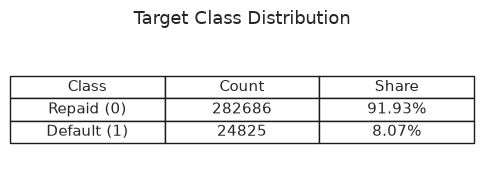

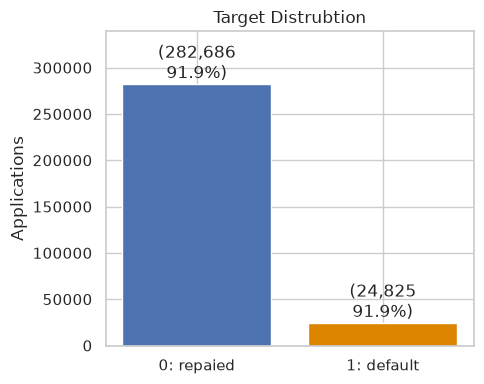

In [42]:
vc = app_train.TARGET.value_counts().sort_index()
print(pd.DataFrame({'count': vc, 'share': (vc/vc.sum()).round(4)}))
print(f'Accuracy of always redicting \'repaid\':{vc[0]/vc.sum():.3f}')
print(f'Imbalance ratio: {vc[0] / vc[1]:.1f} : 1')

#create a table for it
df = pd.DataFrame({
    'Class': ['Repaid (0)','Default (1)'],
    'Count': vc.values,
    'Share': (vc / vc.sum()).map('{:.2%}'.format)
})
accuracy = vc[0] /vc.sum()
imbalance = vc[0] / vc[1]
fig, ax0 = plt.subplots(figsize=(5,2))
ax0.axis('off')

table = ax0.table(
    cellText=df.values.tolist(), # to fix the type error 
    colLabels=df.columns.tolist(),
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1,1.6)
ax0.set_title('Target Class Distribution', fontsize=13, pad=15)
plt.tight_layout()
plt.show()



fig, ax = plt.subplots(figsize=(5,4))
ax.bar(['0: repaied','1: default'], vc.values, color=['#4C72B0','#DD8500'])
for i ,v in enumerate(vc.values):
    ax.text(i, v, f'({v:,}\n{accuracy:.1%})', ha='center', va='bottom')
ax.set_ylabel('Applications'); ax.set_title('Target Distrubtion'); ax.set_ylim(0,vc.max()*1.2)
plt.tight_layout(); 
plt.show()


======================================================================================================
#### A.3.Missing values evaluation
======================================================================================================

67 of 122 columns contain missing values: 41 are more than 50% missing ratio.


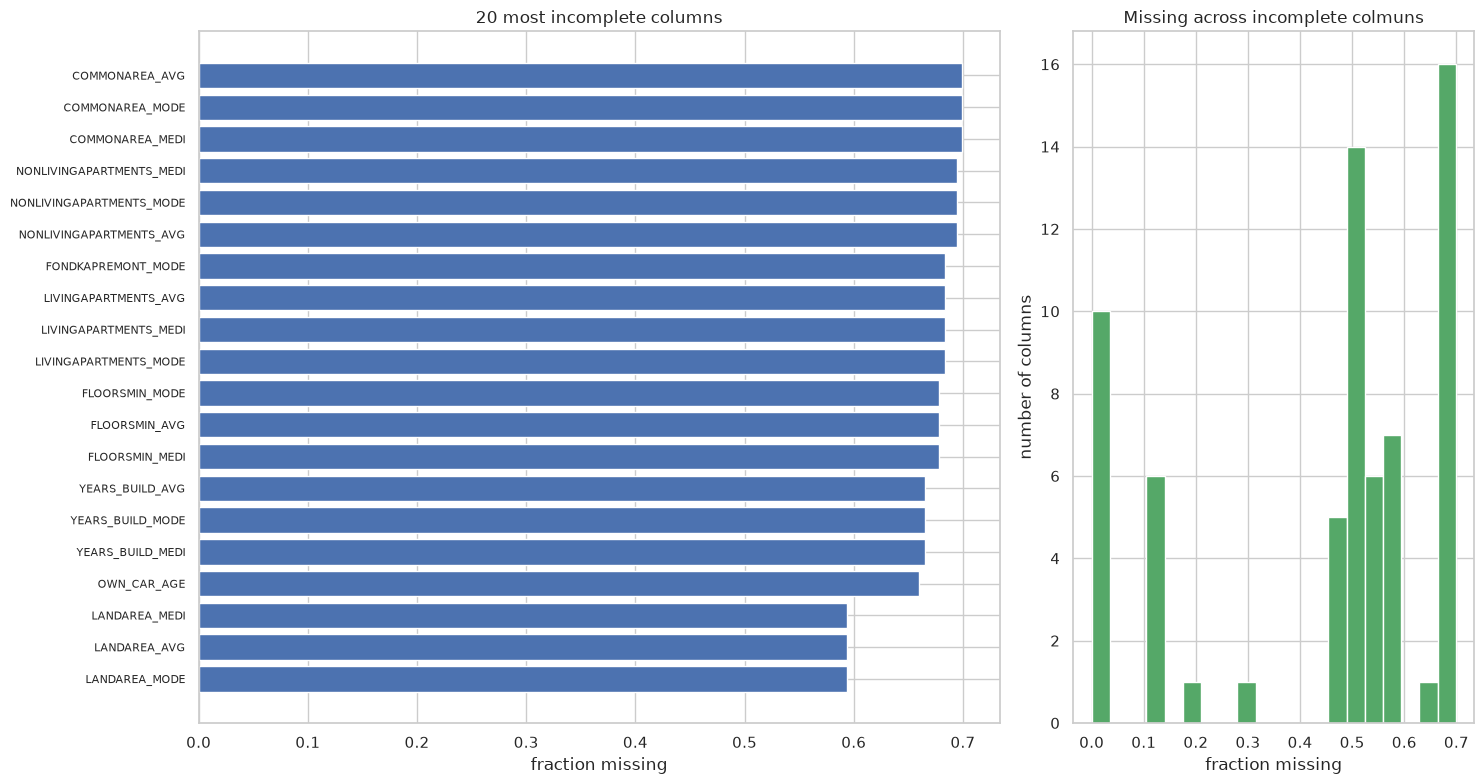

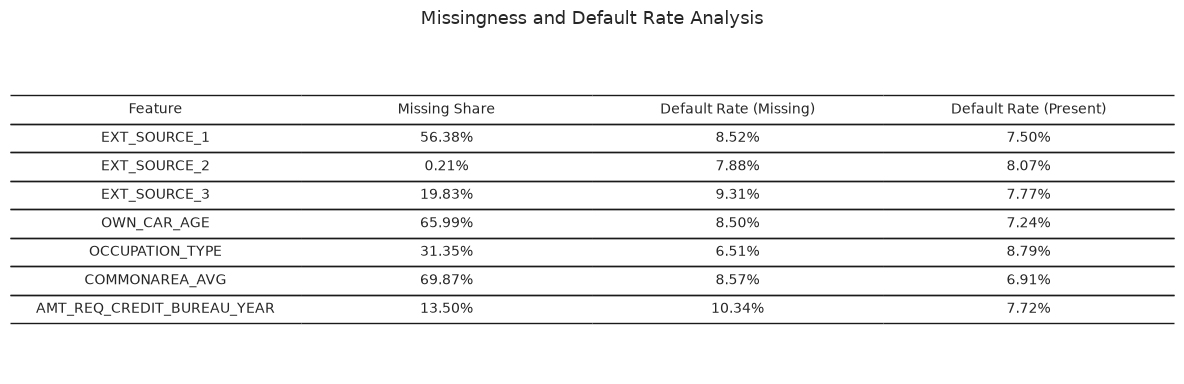

In [43]:
miss = app_train.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f'{len(miss)} of {app_train.shape[1]} columns contain missing values: '
      f'{(miss > 0.5).sum()} are more than 50% missing ratio.'
      ) # 0 is row 1: column

fig, axes = plt.subplots(1,2, figsize = (15,8), gridspec_kw={'width_ratios':[2,1]})
top=miss.head(20)[::-1]
axes[0].barh(top.index, top.values, color=blue)
axes[0].set_xlabel('fraction missing'); axes[0].set_title('20 most incomplete columns')
axes[0].tick_params(axis='y', labelsize=8)
axes[1].hist(miss.values,bins=20, color = green)
axes[1].set_xlabel('fraction missing'); axes[1].set_ylabel('number of columns')
axes[1].set_title('Missing across incomplete colmuns')
plt.tight_layout()
plt.show()


#Compare default rates with and without a value.
check = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'OWN_CAR_AGE', 'OCCUPATION_TYPE',
         'COMMONAREA_AVG', 'AMT_REQ_CREDIT_BUREAU_YEAR']
rows = []
for c in check:
    m = app_train[c].isna()
    rows.append({
        'feature':c,
        'missing_share':m.mean(),
        'default_rate_if_missing':app_train.TARGET[m].mean(),
        'default_rate_if_present':app_train.TARGET[~m].mean()
    })


# Convert to DataFrame
df = pd.DataFrame(rows)

# Format percentages
df_plot = df.copy()
for c in df_plot.columns[1:]:
    df_plot[c] = df_plot[c].map('{:.2%}'.format)

# Create table
fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('off')

table = ax.table(
    cellText=df_plot.values.tolist(),
    colLabels=[
        'Feature',
        'Missing Share',
        'Default Rate (Missing)',
        'Default Rate (Present)'
    ],
    loc='center',
    cellLoc='center',
    edges='horizontal'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

ax.set_title('Missingness and Default Rate Analysis',
             fontsize=13, pad=15)

plt.tight_layout()
plt.show()


======================================================================================================
#### A.4.Statistic summary and anomalies
======================================================================================================

,count,mean,std,min,1%,50%,99%,max
AMT_INCOME_TOTAL,307511.0,168797.92,237123.14,25650.00,45000.00,147150.00,472500.00,1.170000e+08
AMT_CREDIT,307511.0,599026.00,402490.78,45000.00,76410.00,513531.00,1854000.00,4.050000e+06
AMT_ANNUITY,307499.0,27108.57,14493.74,1615.50,6182.91,24903.00,70006.50,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.19,369446.47,40500.00,67500.00,450000.00,1800000.00,4.050000e+06
DAYS_BIRTH,307511.0,-16037.00,4363.99,-25229.00,-24419.00,-15750.00,-8263.00,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.05,141275.77,-17912.00,-10894.90,-1213.00,365243.00,3.652430e+05
DAYS_REGISTRATION,307511.0,-4986.12,3522.89,-24672.00,-13879.00,-4504.00,-50.00,0.000000e+00
DAYS_ID_PUBLISH,307511.0,-2994.20,1509.45,-7197.00,-5447.00,-3254.00,-61.00,0.000000e+00
CNT_CHILDREN,307511.0,0.42,0.72,0.00,0.00,0.00,3.00,1.900000e+01
CNT_FAM_MEMBERS,307509.0,2.15,0.91,1.00,1.00,2.00,5.00,2.000000e+01


,Group,Missing %,Mean,Std,Min,P1,Median,P99,Max,Skew
Features,,,,,,,,,,
AMT_INCOME_TOTAL,Monetary,0.0,"168,797.92","237,123.14","25,650.00","45,000.00","147,150.00","472,500.00","117,000,000.00",391.6
AMT_CREDIT,Monetary,0.0,"599,026.00","402,490.78","45,000.00","76,410.00","513,531.00","1,854,000.00","4,050,000.00",1.2
AMT_ANNUITY,Monetary,0.0,"27,108.57","14,493.74","1,615.50","6,182.91","24,903.00","70,006.50","258,025.50",1.6
AMT_GOODS_PRICE,Monetary,0.1,"538,396.19","369,446.47","40,500.00","67,500.00","450,000.00","1,800,000.00","4,050,000.00",1.3
DAYS_BIRTH,Temporal (days before application),0.0,"-16,037.00","4,363.99","-25,229.00","-24,419.00","-15,750.00","-8,263.00","-7,489.00",-0.1
DAYS_EMPLOYED,Temporal (days before application),0.0,"63,815.05","141,275.77","-17,912.00","-10,894.90","-1,213.00","365,243.00","365,243.00",1.7
DAYS_REGISTRATION,Temporal (days before application),0.0,"-4,986.12","3,522.89","-24,672.00","-13,879.00","-4,504.00",-50.00,0.00,-0.6
DAYS_ID_PUBLISH,Temporal (days before application),0.0,"-2,994.20","1,509.45","-7,197.00","-5,447.00","-3,254.00",-61.00,0.00,0.3
CNT_CHILDREN,Household,0.0,0.42,0.72,0.00,0.00,0.00,3.00,19.00,2.0


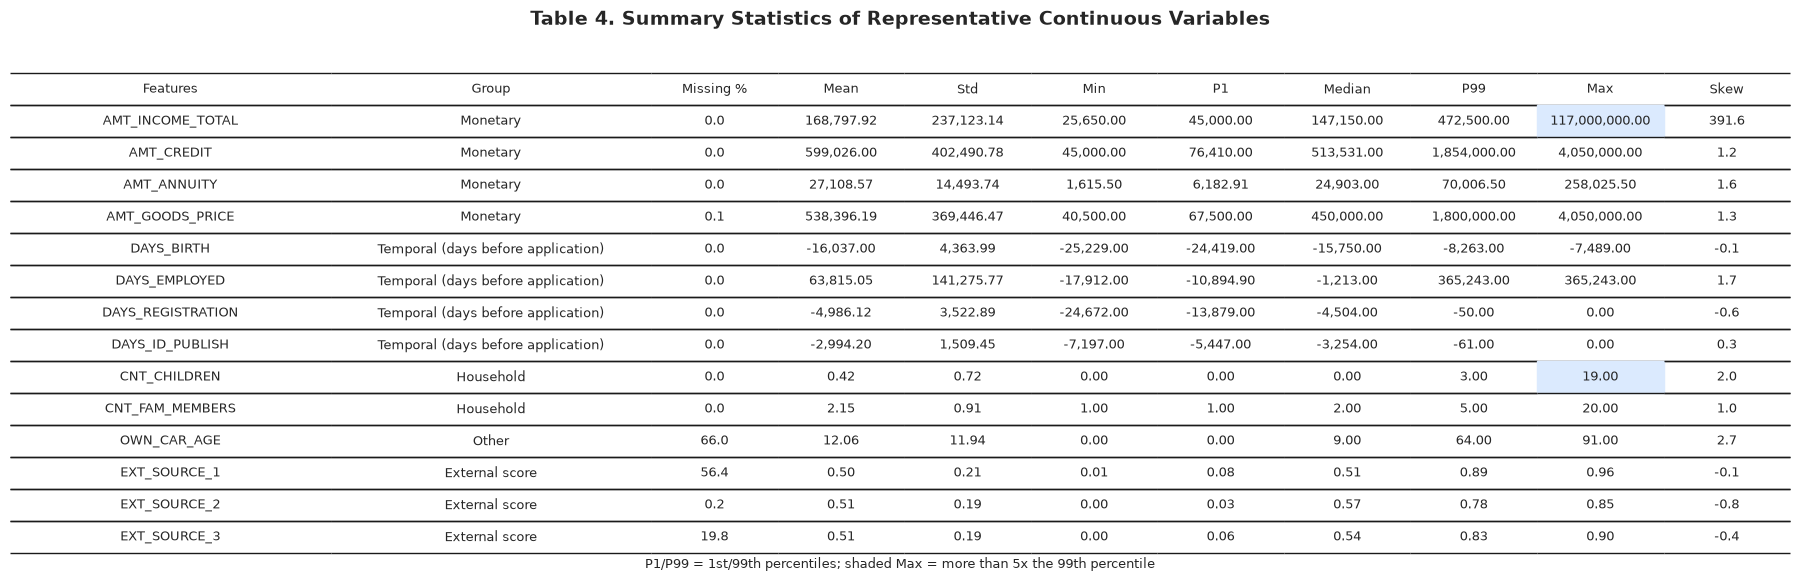

In [44]:
key_features = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
           'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'OWN_CAR_AGE',
           'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
desc = app_train[key_features].describe(percentiles=[0.01,0.5,0.99]).T
display(desc.round(2))

groups = (['Monetary']*4+ ['Temporal (days before application)']*4+['Household']*2+['Other']+['External score']*3)
summary = pd.DataFrame({
    'Group': groups,
    'Missing %': app_train[key_features].isna().mean().mul(100).values,
    'Mean': desc['mean'].values,
    'Std': desc['std'].values,
    'Min': desc['min'].values,
    'P1': desc['1%'].values,
    'Median':desc['50%'].values,
    'P99':desc['99%'].values,
    'Max': desc['max'].values,
    'Skew': app_train[key_features].skew().values
},

index = pd.Index(key_features, name="Features")
)

table4 = (summary.style
          .format('{:,.2f}', subset=['Mean', 'Std', 'Min', 'P1', 'Median', 'P99', 'Max'])
          .format('{:,.1f}', subset=['Missing %', 'Skew'])
          #highlight colmuns where the maxis far beyond the 99th percentile(outliers)
          .apply(lambda r: ['background-color: #dbeafe' if (c == 'Max' and abs(r['Max']) > 5 * abs(r['P99']) and r['P99'] != 0) else ''
                            for c in r.index], axis=1)
        .set_caption('Table 4. Summary statistics of representative continuous variables '
                       '(P1/P99 = 1st/99th percentiles; shaded Max = more than 5x the 99th percentile)')
          .set_table_styles([{'selector': 'caption',
                              'props': 'caption-side: top; font-weight: bold; font-size: 1.05em; text-align: left;'}]))
display(table4)

# Keep feature names as a column
df_plot = summary.reset_index().copy()

# Highlight outliers: Max > 5 × P99
outliers = (
    (summary['P99'] != 0) &
    (summary['Max'].abs() > 5 * summary['P99'].abs())
)

# Format numeric columns
num_cols = ['Mean', 'Std', 'Min', 'P1',
            'Median', 'P99', 'Max']

for c in num_cols:
    df_plot[c] = df_plot[c].map('{:,.2f}'.format)

for c in ['Missing %', 'Skew']:
    df_plot[c] = df_plot[c].map('{:,.1f}'.format)

# Create table
fig, ax = plt.subplots(figsize=(18, 6))
ax.axis('off')
ax.grid(False)

table = ax.table(
    cellText=df_plot.values.tolist(),
    colLabels=df_plot.columns.tolist(),
    loc='center',
    cellLoc='center',
    edges='horizontal'
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.7)

# Highlight Max column for outliers
#max_col = df_plot.columns.get_loc('Max')
max_col = df_plot.columns.tolist().index('Max')

for i, is_outlier in enumerate(outliers):
    if is_outlier:
        #table[(i + 1, max_col)].set_facecolor(	'#dbeafe')
        cell = table[(i+1,max_col)]
        cell.set_facecolor('#dbeafe')
        cell.visible_edges='closed'
        cell.set_edgecolor('#dbeafe')

# Adjust column widths
for i, col in enumerate(df_plot.columns):
    width = 0.19 if col in ['Features', 'Group'] else 0.075

    for row in range(len(df_plot) + 1):
        table[(row, i)].set_width(width)

ax.set_title(
    'Table 4. Summary Statistics of Representative Continuous Variables',
    fontsize=14,
    fontweight='bold',
    pad=20
)

fig.text(
    0.5, 0.04,
    'P1/P99 = 1st/99th percentiles; shaded Max = more than 5x the 99th percentile',
    ha='center',
    fontsize=9
)
plt.tight_layout()
plt.show()

======================================================================================================
#### A.5.Anomaly Decection and Analysis after statistic summary
======================================================================================================

DAYS_EMPLOYED == 365243 in 55,374 rows(18.0%)
Default rate: anomalous 0.0540 vs others 0.0866
NAME_INCOME_TYPE anomalous rows: 
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64
test set: 19.0% anomalous


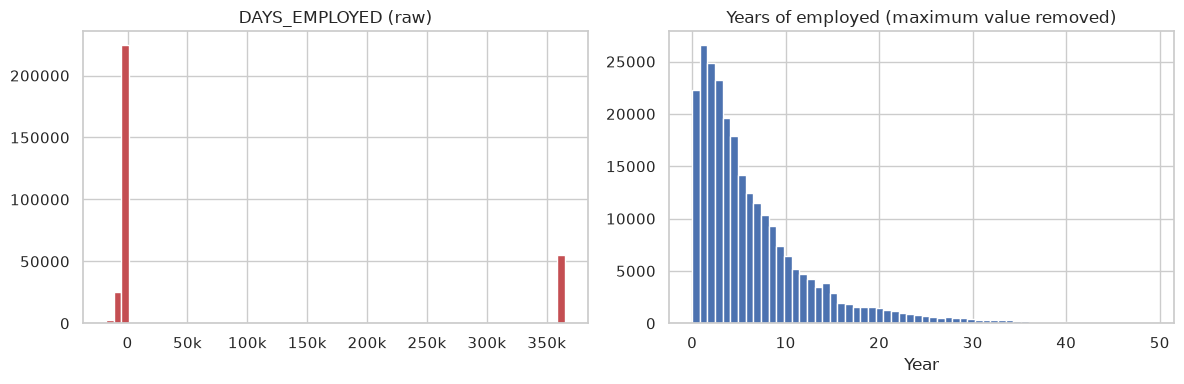


 CODE_GENDER:  {'F': 202448, 'M': 105059, 'XNA': 4}
ORGANIZATION_TYPE=="XNA":  55374 )

Largest incomes:  [117000000, 18000090, 13500000, 9000000, 6750000]
Skewness of monetary columns: 
AMT_INCOME_TOTAL    391.600006
AMT_CREDIT            1.200000
AMT_ANNUITY           1.600000
AMT_GOODS_PRICE       1.300000
dtype: float32


In [45]:
anom = app_train.DAYS_EMPLOYED == 365243
print(f'DAYS_EMPLOYED == 365243 in {anom.sum():,} rows({anom.mean():.1%})') # add thousands separators; add percentage
print(f'Default rate: anomalous {app_train.TARGET[anom].mean():.4f} vs others {app_train.TARGET[~anom].mean():.4f}')
print('NAME_INCOME_TYPE anomalous rows: ');
print(app_train.loc[anom, 'NAME_INCOME_TYPE'].value_counts().head())
print(f'test set: {(app_test.DAYS_EMPLOYED==365243).mean():.1%} anomalous')

fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].hist(app_train.DAYS_EMPLOYED, bins=60, color=red)
# reduce the x-axis scale by x/1000 -> xk
axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x/1000:g}k' if x != 0 else '0')
)
axes[0].set_title('DAYS_EMPLOYED (raw)')
axes[1].hist(-app_train.loc[~anom, 'DAYS_EMPLOYED'] / 365, bins=60, color=blue)
axes[1].set_title('Years of employed (maximum value removed)')
axes[1].set_xlabel('Year')
plt.tight_layout()
plt.show()

# amomaly 2 : placeholder categories
print('\n CODE_GENDER: ', app_train.CODE_GENDER.value_counts().to_dict())
print('ORGANIZATION_TYPE=="XNA": ', ((app_train.ORGANIZATION_TYPE=='XNA')& anom).sum(), ')')

#amonaly 3: extreme incomes / heavy tails
print('\nLargest incomes: ', app_train.AMT_INCOME_TOTAL.nlargest(5).astype(int).tolist())
print('Skewness of monetary columns: ')
print(app_train[['AMT_INCOME_TOTAL','AMT_CREDIT','AMT_ANNUITY','AMT_GOODS_PRICE']].skew().round(1))


======================================================================================================
#### A.6.Distrbution by Target
======================================================================================================

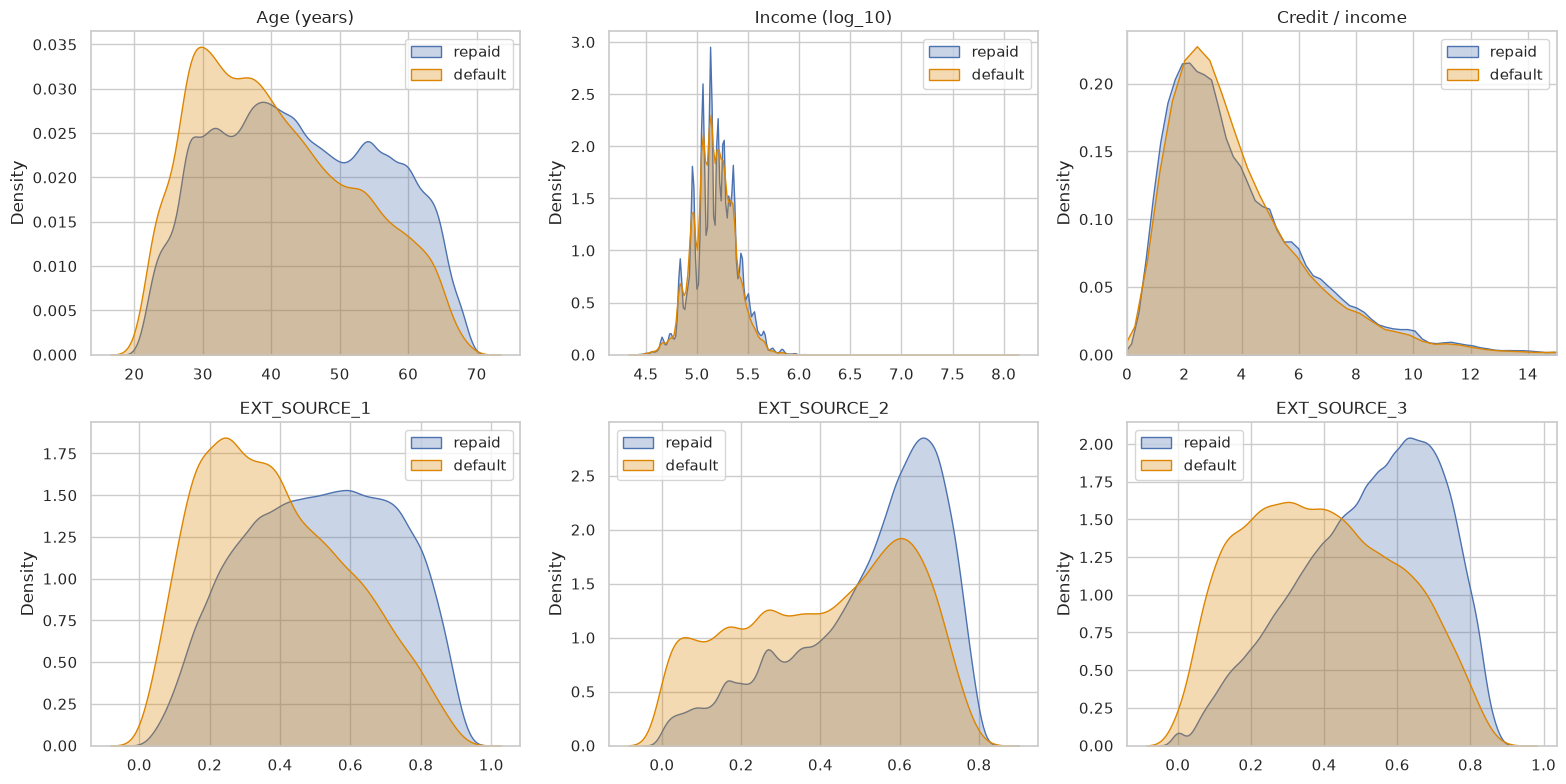

In [46]:
def kde_by_target(ax, s, title, log=False):
    s = np.log10(s.clip(lower=1)) if log else s
    for t, lab, col in [(0, 'repaid', blue), (1, 'default', orange)]:
        sns.kdeplot(s[app_train.TARGET == t].dropna(), ax=ax, label=lab, color=col, fill=True,
                    alpha=.3, common_norm=False)
    ax.set_title(title); ax.set_xlabel(''); ax.legend()

fig, axes = plt.subplots(2,3,figsize=(16,8))
kde_by_target(axes[0, 0], -app_train.DAYS_BIRTH / 365, 'Age (years)')
kde_by_target(axes[0,1], app_train.AMT_INCOME_TOTAL, 'Income (log_10)', log=True)
kde_by_target(axes[0,2], app_train.AMT_CREDIT / app_train.AMT_INCOME_TOTAL, 'Credit / income')
axes[0,2].set_xlim(0,15)
for i,c in enumerate(['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']):
    kde_by_target(axes[1,i], app_train[c],c)
plt.tight_layout()
plt.show()


======================================================================================================
#### A.7.Correlation
======================================================================================================

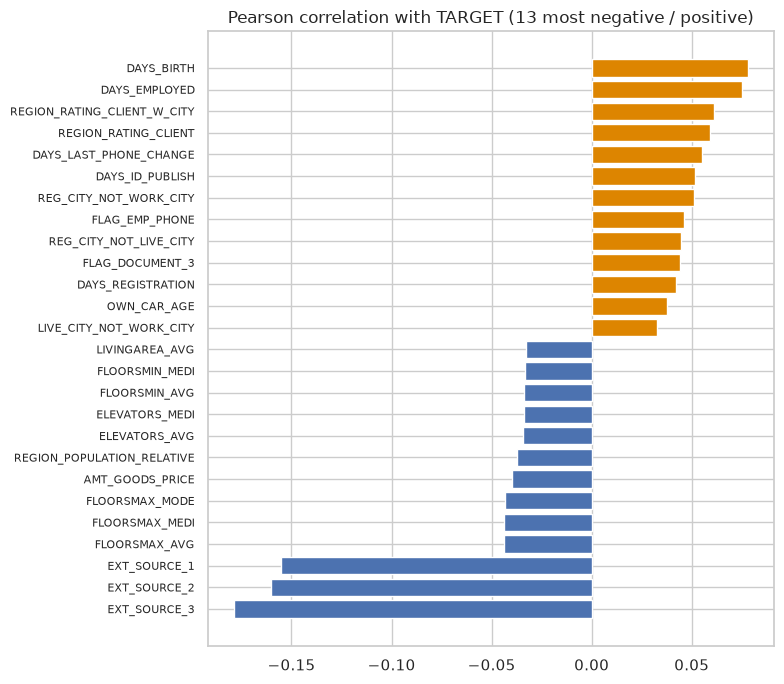

In [47]:
corr_df = app_train.select_dtypes('number').drop(columns=['SK_ID_CURR']).copy() # only select the numerical columns and remove applicant ID
corr_df.loc[corr_df.DAYS_EMPLOYED==365243, 'DAYS_EMPLOYED'] = np.nan # with anomaly of 365243 the value replaces by NaN
corr_t = corr_df.drop(columns='TARGET').corrwith(corr_df.TARGET).dropna().sort_values()

top_corr = pd.concat([corr_t.head(13), corr_t.tail(13)])
fig, ax = plt.subplots(figsize=(8,7))
ax.barh(top_corr.index, top_corr.values,color=np.where(top_corr.values < 0, blue, orange))
ax.set_title('Pearson correlation with TARGET (13 most negative / positive)')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()


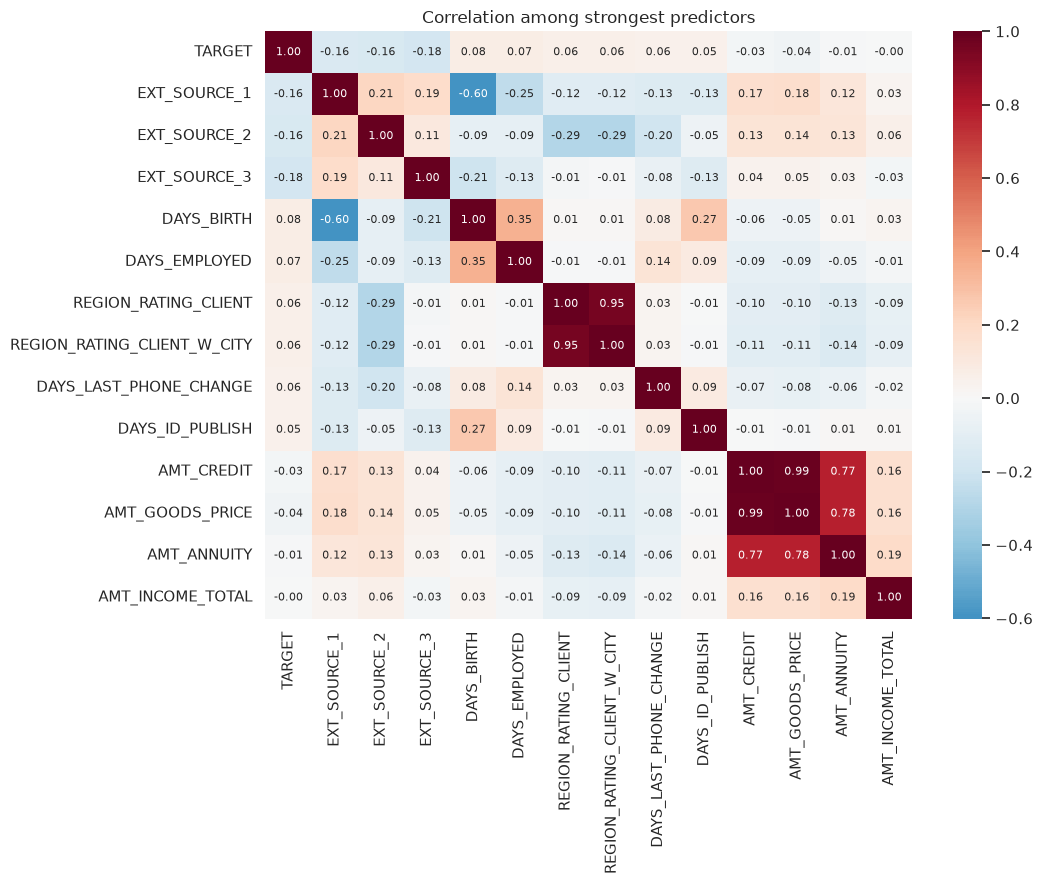

Numeric feature pairs with |r| > 0.95: 45  (mostly the building *_AVG / *_MODE / *_MEDI triplets, plus AMT_CREDIT vs AMT_GOODS_PRICE)


In [48]:
heat_cols = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
             'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'DAYS_LAST_PHONE_CHANGE', 'DAYS_ID_PUBLISH',
             'AMT_CREDIT', 'AMT_GOODS_PRICE', 'AMT_ANNUITY', 'AMT_INCOME_TOTAL']
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_df[heat_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Correlation among strongest predictors'); plt.tight_layout(); plt.show()

# How much redundancy is there among numeric features?
C = corr_df.drop(columns='TARGET').corr().abs().values
iu = np.triu_indices_from(C, k=1)
print(f'Numeric feature pairs with |r| > 0.95: {(C[iu] > 0.95).sum()}  '
      '(mostly the building *_AVG / *_MODE / *_MEDI triplets, plus AMT_CREDIT vs AMT_GOODS_PRICE)')
del corr_df, C; _ = gc.collect()

======================================================================================================
#### A.8.Default rate by Categorical features
- Chooe the top 10 categorical features using mutual information, it may introduce the error, but the choice is based on alogrithm
- $I(X; Y) = H(Y) - H(Y|X)$
- $X$: A categorical feature
- $Y$: the binary targt (TARGET= 0,1)
- $H(Y)$: entropy (uncertainty) of the target before observing the feature.
- $H(Y|X)$: remaining uncertainty about the target after ovserving the feature
- High MI means the feature provides more information about the target

Total categorical features: 16

Top 10 categorical features:
OCCUPATION_TYPE        0.0031
ORGANIZATION_TYPE      0.0027
NAME_INCOME_TYPE       0.0021
NAME_EDUCATION_TYPE    0.0018
CODE_GENDER            0.0015
WALLSMATERIAL_MODE     0.0010
EMERGENCYSTATE_MODE    0.0009
HOUSETYPE_MODE         0.0008
NAME_FAMILY_STATUS     0.0008
NAME_HOUSING_TYPE      0.0006
Name: Mutual Information, dtype: float64


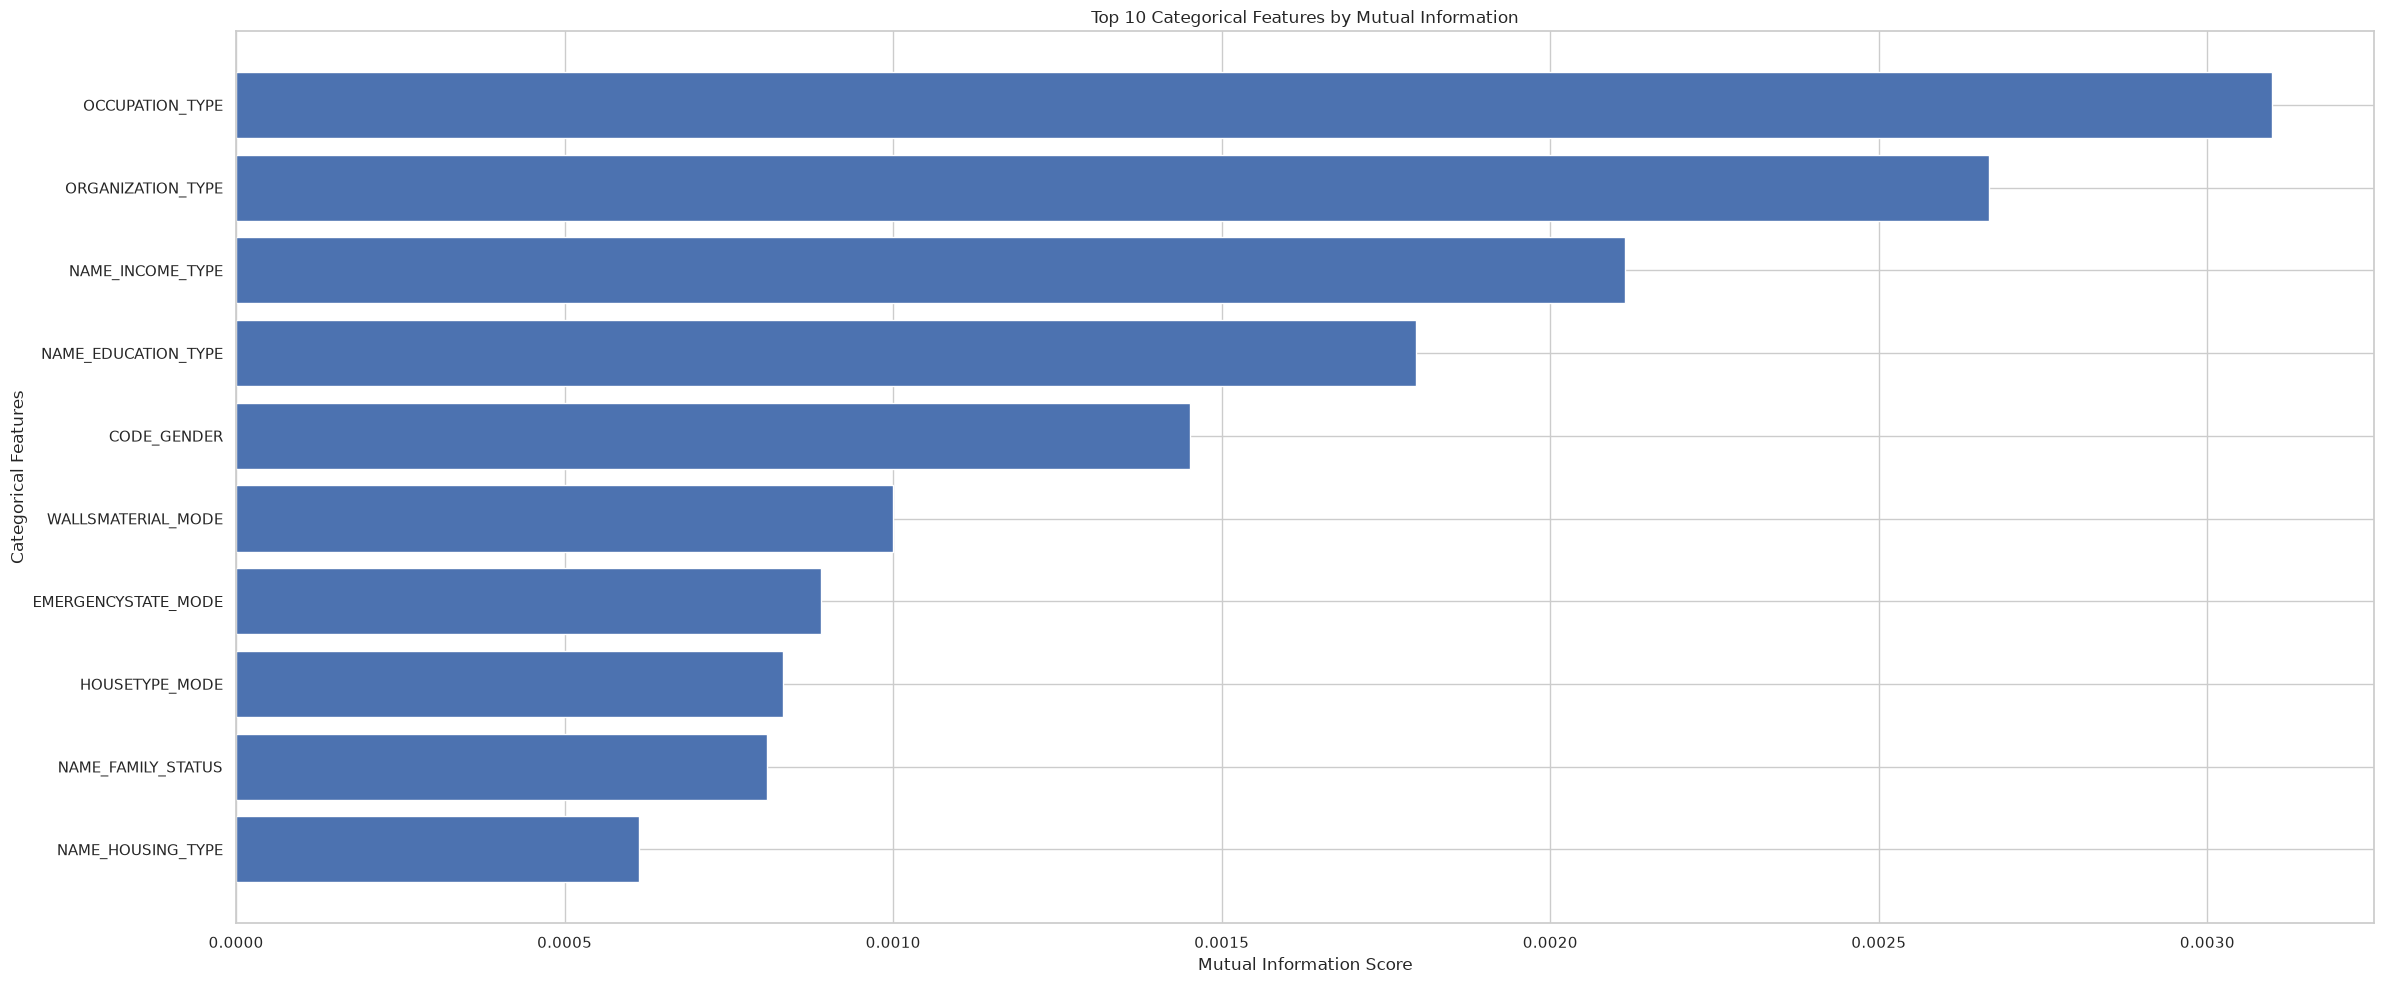

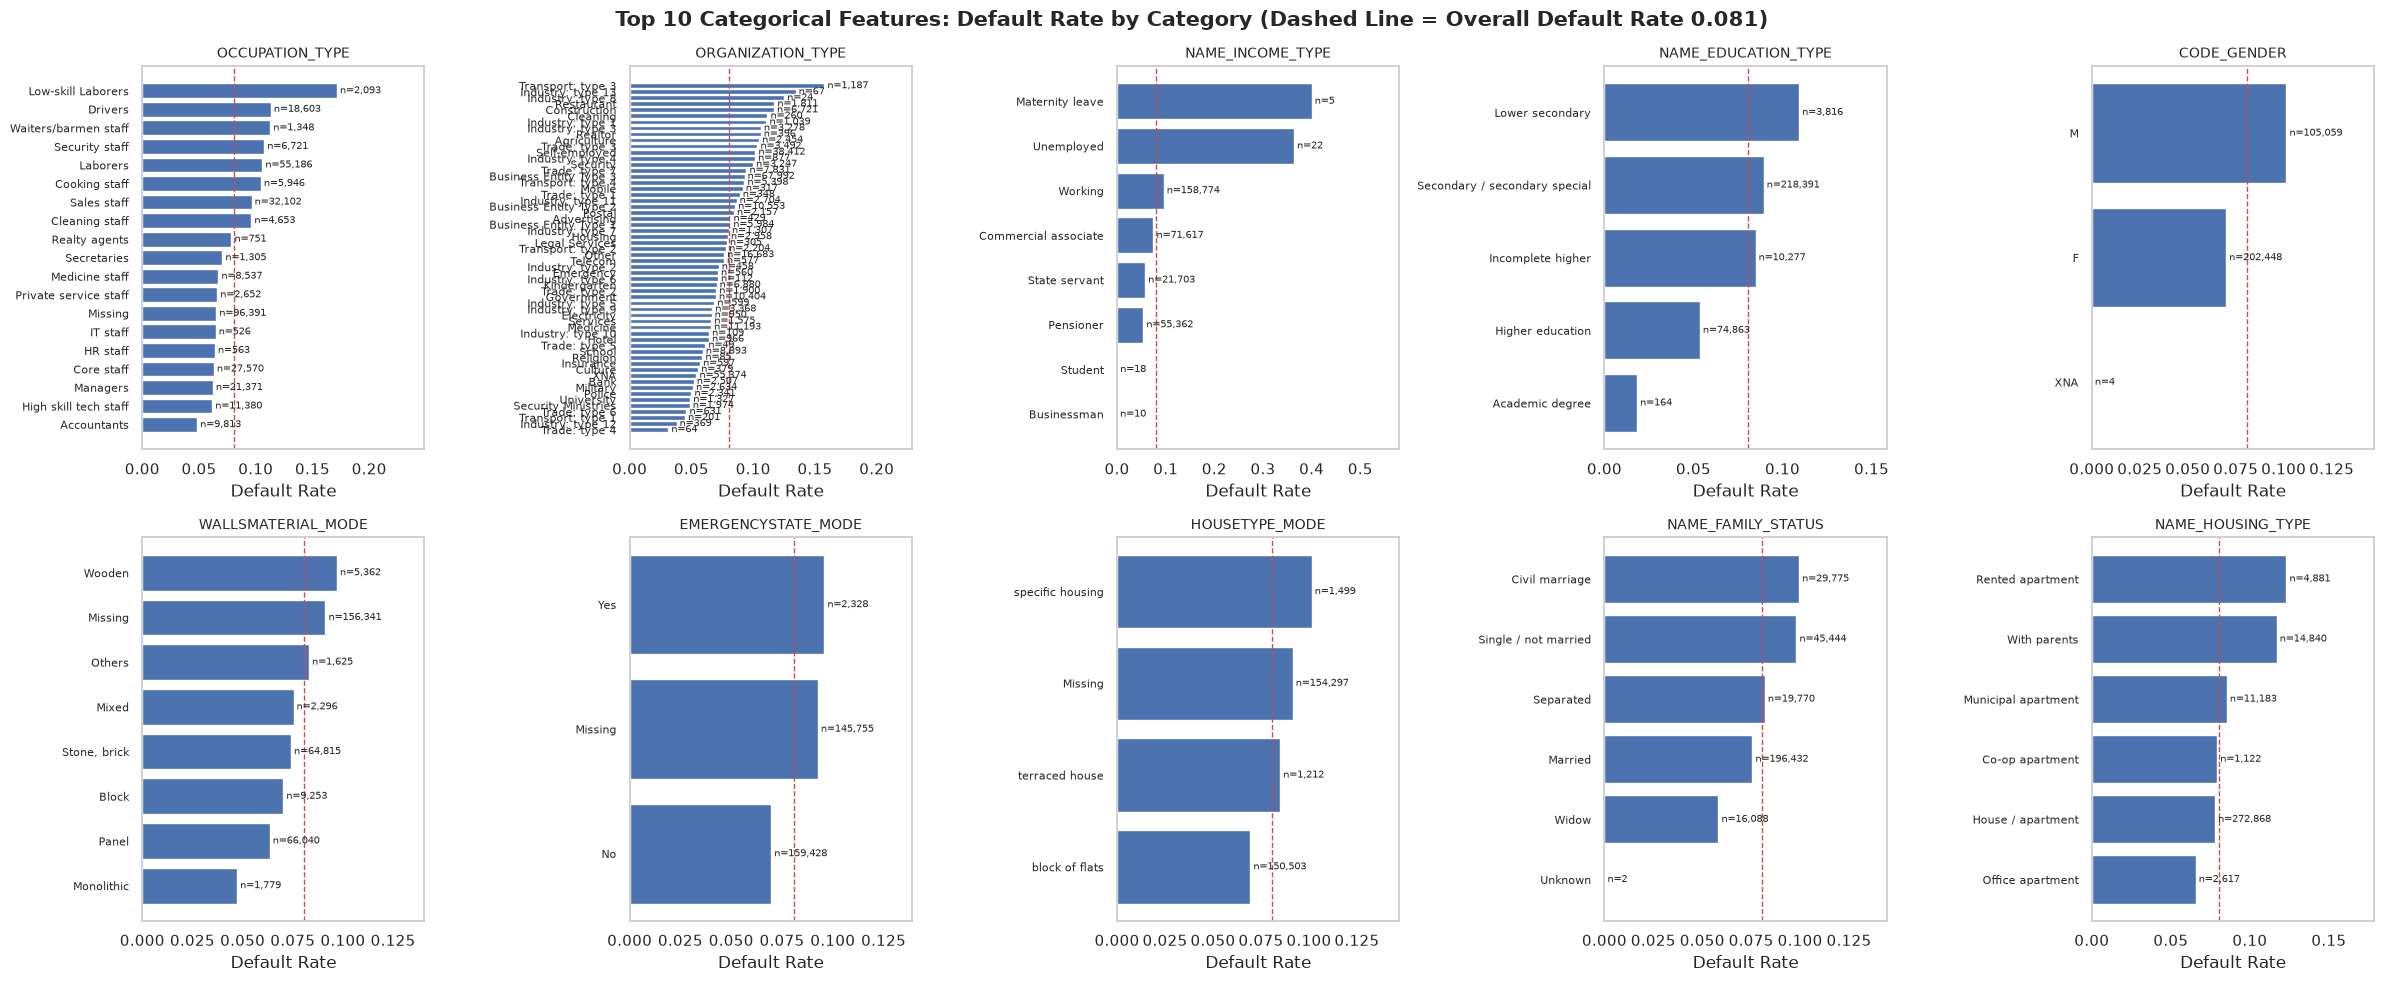

In [49]:


# 1. Identify categorical features
cat_cols = app_train.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print(f'Total categorical features: {len(cat_cols)}')

# 2. Prepare categorical data
X_cat = app_train[cat_cols].fillna('Missing').astype(str)
y = app_train['TARGET']

# 3. Encode categorical features as integers
encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_encoded = encoder.fit_transform(X_cat)

# 4. Calculate mutual information scores
mi = mutual_info_classif(
    X_encoded,
    y,
    discrete_features=True,
    random_state=42
)

# 5. Rank all categorical features
mi_scores = pd.Series(
    mi,
    index=cat_cols,
    name='Mutual Information'
).sort_values(ascending=False)

# 6. Automatically select the top 10
cats_plot = mi_scores.head(10).index.tolist()

print('\nTop 10 categorical features:')
print(mi_scores.head(10).round(4))

# 7. Plot top 10 features
top10 = mi_scores.head(10).sort_values()

fig, ax = plt.subplots(figsize=(24, 10))

ax.barh(
    top10.index,
    top10.to_numpy(dtype=float),
    color=blue
)
# the information of MI score is above
ax.set_xlabel('Mutual Information Score')
ax.set_ylabel('Categorical Features')
ax.set_title('Top 10 Categorical Features by Mutual Information')

plt.tight_layout()
plt.show()

# 8. Final selected features
#print('\ncats_plot =', cats_plot)

# use the picked top 10 to do the analysis
# Select top 10 categorical features by mutual information
cats_plot = mi_scores.head(10).index.tolist()

# Overall default rate
base = app_train['TARGET'].mean()

# Create 2 rows × 5 columns
fig, axes = plt.subplots(2, 5, figsize=(24, 10))

for ax, c in zip(axes.ravel(), cats_plot):

    # Calculate default rate and sample count by category
    g = (
        app_train
        .groupby(app_train[c].fillna('Missing'))['TARGET']
        .agg(['mean', 'size'])
        .sort_values('mean')
    )

    # Horizontal bar chart
    ax.barh(
        g.index.astype(str).tolist(),
        g['mean'].to_numpy(dtype=float),
        color='#4C72B0'
    )

    # Display sample counts
    for y, (m, n) in enumerate(g[['mean', 'size']].itertuples(
        index=False, name=None
    )):
        ax.text(
            m, y,
            f' n={int(n):,}',
            va='center',
            fontsize=7
        )

    # Overall default rate reference line
    ax.axvline(base, color=red, ls='--', lw=1)

    ax.set_title(c, fontsize=10)
    ax.tick_params(axis='y', labelsize=8)
    ax.set_xlabel('Default Rate')

    # Adjust x-axis range
    ax.set_xlim(0, max(g['mean'].max(), base) * 1.45)

    # Remove background grid
    ax.grid(False)

fig.suptitle(
    f'Top 10 Categorical Features: Default Rate by Category '
    f'(Dashed Line = Overall Default Rate {base:.3f})',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


#### A.10.Auxiliary Tables from other tables
- https://www.kaggle.com/code/willkoehrsen/start-here-a-gentle-introduction
- according to the linkage to evaluate other tables information
- each auxiliary table has many rows per applicant , we need to decide how to aggregate them, check their size, fill the gap, and which value should add to the training dataset.

In [50]:
aux_tables = ['bureau', 'previous_application', 'POS_CASH_balance', 'installments_payments', 'credit_card_balance']
train_target = app_train.set_index('SK_ID_CURR').TARGET
rows = []
for name in aux_tables:
    ids = pd.read_csv(f'{DATA_DIR}/{name}.csv', usecols=['SK_ID_CURR'])['SK_ID_CURR']
    ncols = len(pd.read_csv(f'{DATA_DIR}/{name}.csv', nrows=0).columns)
    per_client = ids.value_counts()
    has = train_target.index.isin(per_client.index)
    rows.append({'table': name, 'rows': len(ids), 'columns': ncols,
                 'train_coverage': has.mean(),
                 'median_rows_per_client': per_client.median(),
                 'max_rows_per_client': per_client.max(),
                 'default_rate_with_history': train_target[has].mean(),
                 'default_rate_without_history': train_target[~has].mean()})
bb_rows = len(pd.read_csv(f'{DATA_DIR}/bureau_balance.csv', usecols=['SK_ID_BUREAU']))
aux_summary = pd.DataFrame(rows).set_index('table')
display(aux_summary.style.format({'rows': '{:,}', 'train_coverage': '{:.1%}', 'default_rate_with_history': '{:.4f}',
                                  'default_rate_without_history': '{:.4f}', 'median_rows_per_client': '{:.0f}'}))
print(f'bureau_balance: {bb_rows:,} monthly rows, linked to bureau through SK_ID_BUREAU (not directly to SK_ID_CURR).')
del ids, per_client; _ = gc.collect()


,rows,columns,train_coverage,median_rows_per_client,max_rows_per_client,default_rate_with_history,default_rate_without_history
table,,,,,,,
bureau,"1,716,428",17,85.7%,4,116,0.0773,0.1012
previous_application,"1,670,214",37,94.6%,4,77,0.0819,0.0596
POS_CASH_balance,"10,001,358",8,94.1%,22,295,0.0816,0.0666
installments_payments,"13,605,401",8,94.8%,25,372,0.0819,0.0598
credit_card_balance,"3,840,312",23,28.3%,22,192,0.0867,0.0784


bureau_balance: 27,299,925 monthly rows, linked to bureau through SK_ID_BUREAU (not directly to SK_ID_CURR).


Table 6. Largest standardised mean differences (test - train) / std_train


,std_mean_diff,missing_rate_diff
FLAG_EMAIL,0.458,0.000
AMT_REQ_CREDIT_BUREAU_QRT,0.354,-0.011
AMT_REQ_CREDIT_BUREAU_MON,-0.282,-0.011
AMT_GOODS_PRICE,-0.205,-0.001
AMT_CREDIT,-0.204,0.000
FLAG_DOCUMENT_3,0.169,0.000
AMT_ANNUITY,0.160,0.000
AMT_REQ_CREDIT_BUREAU_WEEK,-0.154,-0.011
DAYS_LAST_PHONE_CHANGE,-0.139,-0.000
FLAG_DOCUMENT_16,-0.100,0.000


Table 7. Categorical levels whose share differs most between train and test


,train,test,abs_diff
NAME_CONTRACT_TYPE = Cash loans,0.905,0.991,0.086
NAME_CONTRACT_TYPE = Revolving loans,0.095,0.009,0.086
WEEKDAY_APPR_PROCESS_START = TUESDAY,0.175,0.200,0.025
NAME_FAMILY_STATUS = Married,0.639,0.662,0.024
EMERGENCYSTATE_MODE = No,0.518,0.537,0.019
EMERGENCYSTATE_MODE = Missing,0.474,0.456,0.018
WALLSMATERIAL_MODE = Missing,0.508,0.490,0.018
HOUSETYPE_MODE = Missing,0.502,0.485,0.017


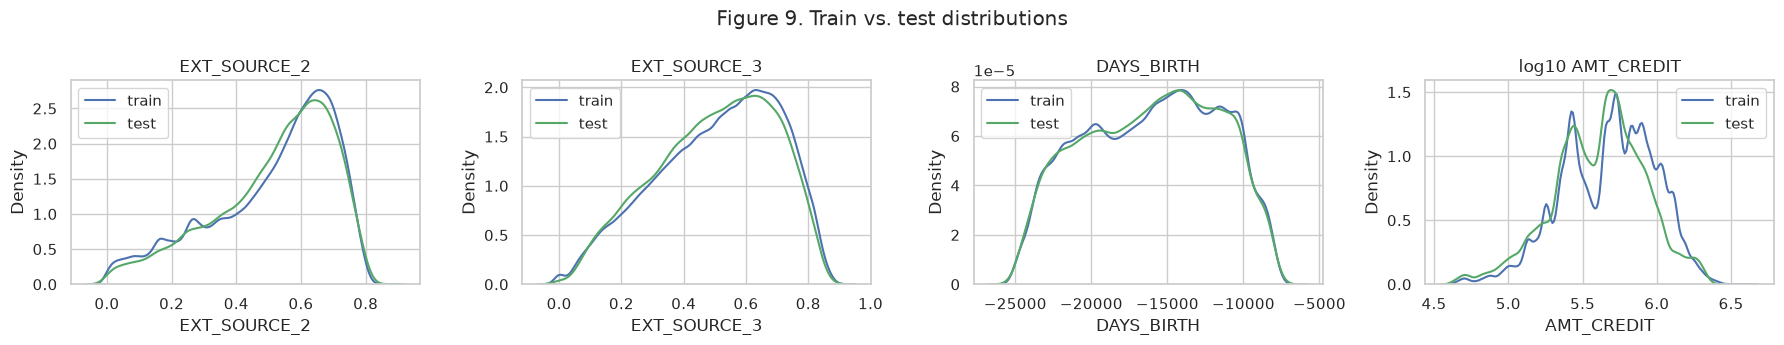

In [51]:
shift_num = app_test.select_dtypes('number').columns.drop('SK_ID_CURR')
smd = ((app_test[shift_num].mean() - app_train[shift_num].mean()) / app_train[shift_num].std()).dropna()
miss_diff = (app_test[shift_num].isna().mean() - app_train[shift_num].isna().mean())
shift_tbl = pd.DataFrame({'std_mean_diff': smd, 'missing_rate_diff': miss_diff}).loc[smd.abs().sort_values(ascending=False).index]
print('Table 6. Largest standardised mean differences (test - train) / std_train')
display(shift_tbl.head(10).round(3))

cat_shift = []
for c in cat_cols_raw:
    a = app_train[c].fillna('Missing').value_counts(normalize=True)
    b = app_test[c].fillna('Missing').value_counts(normalize=True)
    d = pd.concat([a, b], axis=1, keys=['train', 'test']).fillna(0)
    d['abs_diff'] = (d.test - d.train).abs()
    d.index = [f'{c} = {v}' for v in d.index]
    cat_shift.append(d)
cat_shift = pd.concat(cat_shift).sort_values('abs_diff', ascending=False)
print('Table 7. Categorical levels whose share differs most between train and test')
display(cat_shift.head(8).round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (c, f) in zip(axes, [('EXT_SOURCE_2', None), ('EXT_SOURCE_3', None), ('DAYS_BIRTH', None), ('AMT_CREDIT', np.log10)]):
    for df_, lab, col in [(app_train, 'train', '#4C72B0'), (app_test, 'test', '#55A868')]:
        s = df_[c].dropna(); s = f(s) if f else s
        sns.kdeplot(s, ax=ax, label=lab, color=col, common_norm=False)
    ax.set_title(c if f is None else f'log10 {c}'); ax.legend()
fig.suptitle('Figure 9. Train vs. test distributions'); plt.tight_layout(); plt.show()

In [52]:
age_rate = app_train.TARGET.groupby(pd.cut(-app_train.DAYS_BIRTH / 365.25, bins=range(20, 75, 5)), observed=True).mean()
gender_rate = app_train.groupby('CODE_GENDER').TARGET.mean()
facts = {
    'labelled applications': f'{len(app_train):,}',
    'test applications': f'{len(app_test):,}',
    'default rate': f'{app_train.TARGET.mean():.2%}',
    'imbalance (repaid : default)': f'{vc[0] / vc[1]:.1f} : 1',
    'columns with missing values': f'{len(miss)} of {app_train.shape[1]}',
    'columns > 50% missing': f'{(miss > 0.5).sum()}',
    'DAYS_EMPLOYED placeholder rows': f'{anom.sum():,} ({anom.mean():.1%})',
    'default rate, placeholder vs. other': f'{app_train.TARGET[anom].mean():.2%} vs. {app_train.TARGET[~anom].mean():.2%}',
    'strongest negative correlations': ', '.join(f'{k} ({v:+.3f})' for k, v in corr_t.head(3).items()),
    'strongest positive correlations': ', '.join(f'{k} ({v:+.3f})' for k, v in corr_t.tail(3)[::-1].items()),
    'default rate youngest / oldest age band': f'{age_rate.iloc[0]:.2%} ({age_rate.index[0]}) / {age_rate.iloc[-1]:.2%} ({age_rate.index[-1]})',
    'default rate M / F': f"{gender_rate.get('M', np.nan):.2%} / {gender_rate.get('F', np.nan):.2%}",
    'max AMT_INCOME_TOTAL vs. 99th pct': f"{app_train.AMT_INCOME_TOTAL.max():,.0f} vs. {app_train.AMT_INCOME_TOTAL.quantile(.99):,.0f}",
    'aux-table coverage of applicants': ', '.join(f'{k}: {v:.0%}' for k, v in aux_summary.train_coverage.items()),
    'largest train/test shift': f"{shift_tbl.index[0]} (SMD {shift_tbl.std_mean_diff.iloc[0]:+.2f}); {cat_shift.index[0]} ({cat_shift.train.iloc[0]:.1%} -> {cat_shift.test.iloc[0]:.1%})",
}
print('Table 8. Key EDA figures')
display(pd.Series(facts).to_frame('value'))

Table 8. Key EDA figures


,value
labelled applications,"307,511"
test applications,"48,744"
default rate,8.07%
imbalance (repaid : default),11.4 : 1
columns with missing values,67 of 122
columns > 50% missing,41
DAYS_EMPLOYED placeholder rows,"55,374 (18.0%)"
"default rate, placeholder vs. other",5.40% vs. 8.66%
strongest negative correlations,"EXT_SOURCE_3 (-0.179), EXT_SOURCE_2 (-0.160), ..."
strongest positive correlations,"DAYS_BIRTH (+0.078), DAYS_EMPLOYED (+0.075), R..."


In [55]:


base_rate = app_train.TARGET.mean()

# Table 8a: numeric signals (placeholder removed from DAYS_EMPLOYED)
# signal_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
#                'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'DAYS_LAST_PHONE_CHANGE', 'DAYS_ID_PUBLISH']
# sig = app_train[signal_cols + ['TARGET']].copy()
# sig['DAYS_EMPLOYED'] = sig.DAYS_EMPLOYED.where(sig.DAYS_EMPLOYED != DAYS_PLACEHOLDER)
# rows = []
# for c in signal_cols:
#     ok = sig[c].notna()
#     rows.append({'feature': c,
#                  'pearson_r': sig.loc[ok, c].corr(sig.loc[ok, 'TARGET']),
#                  'univariate_auc': roc_auc_score(sig.loc[ok, 'TARGET'], sig.loc[ok, c]),
#                  'mean_if_repaid': sig.loc[ok & (sig.TARGET == 0), c].mean(),
#                  'mean_if_default': sig.loc[ok & (sig.TARGET == 1), c].mean(),
#                  'missing_%': 100 * (~ok).mean()})
# table8a = pd.DataFrame(rows).set_index('feature')
# table8a['signal_strength'] = (table8a.univariate_auc - 0.5).abs()
# table8a = table8a.sort_values('signal_strength', ascending=False).drop(columns='signal_strength')
# print('Table 8a. Strength of the main numeric signals')
# display(table8a.round(3))

# Table 8b: default rate by age band
age_years = -app_train.DAYS_BIRTH / 365.25
table8b = (app_train.groupby(pd.cut(age_years, bins=range(20, 75, 5)), observed=True).TARGET
           .agg(n='size', default_rate='mean'))
table8b['lift_vs_overall'] = table8b.default_rate / base_rate
print(f'Table 8b. Default rate by age band (overall rate {base_rate:.2%})')
display(table8b.style.format({'n': '{:,}', 'default_rate': '{:.2%}', 'lift_vs_overall': '{:.2f}x'}))

# Table 8c: default rate per categorical level; levels below the minimum size are hidden as too noisy
min_level_share = 0.005
cat_signal = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE',
              'NAME_HOUSING_TYPE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS']
parts = []
for c in cat_signal:
    g = app_train.groupby(app_train[c].fillna('Missing')).TARGET.agg(n='size', default_rate='mean')
    g = g[g.n >= min_level_share * len(app_train)].sort_values('default_rate', ascending=False)
    g.index = pd.MultiIndex.from_product([[c], g.index], names=['feature', 'level'])
    parts.append(g)
table8c = pd.concat(parts)
table8c['lift_vs_overall'] = table8c.default_rate / base_rate
print(f'Table 8c. Default rate by categorical level (levels with >= {min_level_share:.1%} of applications)')
display(table8c.style.format({'n': '{:,}', 'default_rate': '{:.2%}', 'lift_vs_overall': '{:.2f}x'})
        .background_gradient(subset=['lift_vs_overall'], cmap='RdBu_r', vmin=0.5, vmax=1.5))

Table 8b. Default rate by age band (overall rate 8.07%)


,n,default_rate,lift_vs_overall
DAYS_BIRTH,,,
"(20, 25]","12,233",12.29%,1.52x
"(25, 30]","32,953",11.13%,1.38x
"(30, 35]","39,476",10.27%,1.27x
"(35, 40]","42,873",8.96%,1.11x
"(40, 45]","41,388",7.83%,0.97x
"(45, 50]","35,193",7.42%,0.92x
"(50, 55]","34,997",6.67%,0.83x
"(55, 60]","33,112",5.54%,0.69x
"(60, 65]","27,410",5.28%,0.65x


Table 8c. Default rate by categorical level (levels with >= 0.5% of applications)


======================================================================================================
## A.10.Initial findings and Hypothesis of Project
**Imbalance**. around 8.1% of applications are defaults (24825 / 307511, A.2.Target Balance). 

**Missing data is normal and widespread among features**.The largest block is the ~47 normalized building descriptors (`*_AVG` `*_MODE`, `*_MEDI`), which are 50–70% missing and go missing *together*. `EXT_SOURCE_1` (~56%) and `OWN_CAR_AGE` (~66%) are also mostly missing. Missingness is not random: applicants without `EXT_SOURCE_1`/`EXT_SOURCE_3` or without building information default more often. **Hypothesis**: we can impute and flag the missing data (mean, median) rather than dropping data. (ref: A.3.Missing values evaluation)

**Anomalies**. DAYS_EMPLOYED = 365243 shows 18% of rows (ref: A.5.Anomaly Decection and Analysis after statistic summary)

**Strongest raw signals**. The three eternal scores are the most predictive features, and their class-conditonal densities separate visibly. Younger applicants default more (12.29% in the 20-25 years vs 3.66% in the 60-70 years)

**Redundancy**. Many numeric pairs have |r| > 0.95 (AMT_CREDIT, AMT_GOODS_PRICE). Highly collinear inputs destabilise logistic-regression coefficients and add cost to the SVM.

**Auxiliary tables**. Coverage varies a lot: most applicants have bureau and previous-application records, but 28.3% applicants have credit-card history. **hypothesis**: (1) repayment behavior (st: late or partial payments, past-due amounts) (2) Missing credit History (record counts are filled with 0 and the corresponding missing pattern is flagged.)

# (b) Data Preprocessing & Cleaning

| Step | What | Fitted on |
|---|---|---|
| b.1 | Stratified 80/20 split of `application_train` | — |
| b.2 | Row-wise cleaning and domain features on the application table | nothing fitted (pure row-wise formulas) |
| b.3 | Aggregate the six auxiliary tables to one row per `SK_ID_CURR` and left-join | rare-category vocabularies: train-split clients only |
| b.4 | Drop very-sparse and near-constant columns; add de-duplicated missing indicators | train split |
| b.5 | Median imputation | train split |
| b.6 | Clip to the 0.1st/99.9th percentiles, `log1p` on skewed non-negative columns | train split |
| b.7 | Drop one of every pair with \|r\| > 0.98 | train split |
| b.8 | Standardise numeric features; one-hot encode categoricals (rare levels grouped) | train split |

## b.1 Stratified train/validation split
The split is made first so that every later fitted step can be restricted to training rows.

In [58]:
# split the dataset
"""
tr_idx contains row positioins, not SK_ID_CURR, it is a row index not the ID
train_ids is unique among different files
"""
y_all = app_train.TARGET.values.astype(np.int8) # save memory 
tr_idx, va_idx = train_test_split(np.arange(len(app_train)), test_size=CONFIG['val_size'], stratify=y_all, random_state=CONFIG['seed'])
train_ids = set(app_train.SK_ID_CURR.values[tr_idx])

print(f'train {len(tr_idx):,} rows, default rate {y_all[tr_idx].mean():.4f}')
print(f'valid {len(va_idx):,} rows, default rate {y_all[va_idx].mean():.4f}')

train 246,008 rows, default rate 0.0807
valid 61,503 rows, default rate 0.0807


## b.2 Application table: cleaning and domain features
- DAYS_EMPLOYED = 365243 change to NaN + flag DAYS_EMPLOYED_ANOM
- CODE_GENDER = "XNA" $\rightarrow$ missing
- Affordable ratios: credit / income, annuity / income, goods / credit, income / family member
- external-score mean, min, max, std et al.
- Number of documents provided.

In [ ]:
def engineer_application(app):
    #function creates 13 new features:
    df = app.copy() # create an individual data copy
    df['DAYS_EMPLOYED_ANOM'] = (df.DAYS_EMPLOYED==365243).astype(np.int8)
    df['DAYS_EMPLOYED'] = df.DAYS_EMPLOYED.where(df.DAYS_EMPLOYED != 365243)
    df['CODE_GENDER'] = df.CODE_GENDER.where(df.CODE_GENDER != 'XNA')

    df['CREDIT_INCOME_RATIO'] = df.AMT_CREDIT / df.AMT_INCOME_TOTAL
    df['ANNUITY_INCOME_RATIO'] = df.AMT_ANNUITY / df.AMT_INCOME_TOTAL
    df['ANNUITY_CREDIT_RATIO'] = df.AMT_ANNUITY / df.AMT_CREDIT
    df['GOODS_CREDIT_RATIO'] = df.AMT_GOODS_PRICE / df.AMT_CREDIT
    df['INCOME_PER_PERSON'] = df.AMT_INCOME_TOTAL / df.CNT_FAM_MEMBERS
    df['EMPLOYED_AGE_RATIO'] = df.DAYS_EMPLOYED / df.DAYS_BIRTH

    ext = df[['EXT_SOURCE_1', 'EXT_SOURCE_2','EXT_SHOURCE_3']]
    df['EXT_MEAN'] = ext.mean(axis=1)
    df['EXT_MIN'] = ext.min(axis=1)
    df['EXT_MAX'] = ext.max(axis=1)
    df['EXT_STD'] = ext.std(axis=1)
    df['EXT_PROD'] = ext.prod(axis=1)
    df['EXT_N_MISSING'] = ext.isna().sum(axis=1).astype(np.int8)

    doc_cols = [c for c in df.columns if c.startswitch('FLAG_DOCUMENT_')]
    df['doc_count'] = df[doc_cols].sum(axis=1).astype(np.int8)

    return df


## b.3 Combine the auxiliary tables
- bureau_balance $\rightarrow$ bureau $\rightarrow$ applicants
- previous_application. 365243 in the DAYS_columns  $\rightarrow$ NaN. 
- installation_payments
- POS_CASH_balance
- credit_card_balance: balance, limit, utilisation, drawing, payment vs requirement minimum, days past due, overall and over the last 12 months

Leakage. the aggregates use only each applicant's own history and never the target, so they are row-wise features.

In [ ]:
def sanitize(name):
    return re.sub(r'[^A-Za-z0-9]+', '_', str(name)).strip('_').upper()

def clean_inf(df):
    num = df.select_dtypes('number').columns
    df[num] = df[num].replace([np.inf, -np.inf], np.nan)
    return df

def num_aggs(df, spec, prefix, key='SK_ID_CURR'):
    g = df.groupby(key).agg(spec)
    g.columns = [f'{prefix}_{c}_{s}'.upper() for c, s in g.columns]
    return g

def lump_rare(df, cols, ref_mask, min_share=0.01):
    
    for c in cols:
        s = df[c].astype(object).where(df[c].notna(), 'Missing')
        share = s[ref_mask].value_counts(normalize=True)
        df[c] = s.where(s.isin(share[share >= min_share].index), 'Other')
    return df

def cat_shares(df, cols, prefix, key='SK_ID_CURR'):
    d = pd.get_dummies(df[cols].astype(str), dtype=np.float32)
    d[key] = df[key].values
    g = d.groupby(key).mean()
    g.columns = [f'{prefix}_{sanitize(c)}_SHARE' for c in g.columns]
    return g





In [ ]:
def bureau_features(train_ids):
    bb = load('bureau_balance', cat=True)
    late = bb.STATUS.isin(['1', '2', '3', '4', '5'])
    bb['DPD'] = late.astype(np.float32)
    bb['DPD30'] = bb.STATUS.isin(['2', '3', '4', '5']).astype(np.float32)
    bb['UNKNOWN'] = (bb.STATUS == 'X').astype(np.float32)
    bb['DPD_LAST12'] = np.where(bb.MONTHS_BALANCE >= -12, bb.DPD, np.nan).astype(np.float32)
    bb_agg = bb.groupby('SK_ID_BUREAU').agg(BB_MONTHS=('MONTHS_BALANCE', 'size'),
                                             BB_DPD_SHARE=('DPD', 'mean'),
                                             BB_DPD30_EVER=('DPD30', 'max'),
                                             BB_UNKNOWN_SHARE=('UNKNOWN', 'mean'),
                                             BB_DPD_LAST12=('DPD_LAST12', 'max'))
    del bb, late; gc.collect()

    bu = load('bureau', cat=True)
    bu = bu.merge(bb_agg, left_on='SK_ID_BUREAU', right_index=True, how='left')
    del bb_agg; gc.collect()
    bu['DEBT_CREDIT_RATIO'] = bu.AMT_CREDIT_SUM_DEBT / bu.AMT_CREDIT_SUM
    bu['CREDIT_DURATION'] = bu.DAYS_CREDIT_ENDDATE - bu.DAYS_CREDIT
    bu['ENDDATE_DIFF'] = bu.DAYS_ENDDATE_FACT - bu.DAYS_CREDIT_ENDDATE   # >0: closed later than planned
    bu = clean_inf(bu)

    agg = num_aggs(bu, {
        'DAYS_CREDIT': ['min', 'max', 'mean'],
        'DAYS_CREDIT_ENDDATE': ['max', 'mean'],
        'DAYS_CREDIT_UPDATE': ['mean'],
        'CREDIT_DAY_OVERDUE': ['max', 'mean'],
        'AMT_CREDIT_MAX_OVERDUE': ['max', 'mean'],
        'AMT_CREDIT_SUM': ['sum', 'mean', 'max'],
        'AMT_CREDIT_SUM_DEBT': ['sum', 'mean'],
        'AMT_CREDIT_SUM_OVERDUE': ['sum', 'max'],
        'AMT_CREDIT_SUM_LIMIT': ['sum', 'mean'],
        'CNT_CREDIT_PROLONG': ['sum'],
        'DEBT_CREDIT_RATIO': ['mean', 'max'],
        'CREDIT_DURATION': ['mean'],
        'ENDDATE_DIFF': ['mean'],
        'BB_MONTHS': ['mean', 'sum'],
        'BB_DPD_SHARE': ['mean', 'max'],
        'BB_DPD30_EVER': ['mean', 'max'],
        'BB_UNKNOWN_SHARE': ['mean'],
        'BB_DPD_LAST12': ['mean', 'max'],
    }, 'BURO')
    agg['BURO_COUNT'] = bu.groupby('SK_ID_CURR').size()

    ref = bu.SK_ID_CURR.isin(train_ids)
    bu = lump_rare(bu, ['CREDIT_ACTIVE', 'CREDIT_TYPE'], ref)
    agg = agg.join(cat_shares(bu, ['CREDIT_ACTIVE', 'CREDIT_TYPE'], 'BURO'))

    act = bu[bu.CREDIT_ACTIVE == 'Active']
    agg = agg.join(num_aggs(act, {'AMT_CREDIT_SUM': ['sum'], 'AMT_CREDIT_SUM_DEBT': ['sum'],
                                  'AMT_CREDIT_SUM_OVERDUE': ['sum'], 'DAYS_CREDIT_ENDDATE': ['max', 'mean'],
                                  'DEBT_CREDIT_RATIO': ['mean']}, 'BURO_ACT'))
    agg['BURO_ACT_COUNT'] = act.groupby('SK_ID_CURR').size()
    agg['BURO_ACT_DEBT_CREDIT_RATIO'] = agg.BURO_ACT_AMT_CREDIT_SUM_DEBT_SUM / agg.BURO_ACT_AMT_CREDIT_SUM_SUM

    clo = bu[bu.CREDIT_ACTIVE == 'Closed']
    agg = agg.join(num_aggs(clo, {'DAYS_CREDIT': ['max'], 'DAYS_ENDDATE_FACT': ['max'],
                                  'AMT_CREDIT_SUM': ['mean']}, 'BURO_CLO'))
    agg['BURO_CLO_COUNT'] = clo.groupby('SK_ID_CURR').size()
    del bu, act, clo; gc.collect()
    return clean_inf(agg).astype(np.float32)

In [ ]:
def previous_features(train_ids):
    pa = load('previous_application', cat=True)
    for c in ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']:
        pa[c] = pa[c].where(pa[c] != 365243)
    pa['APP_CREDIT_RATIO'] = pa.AMT_APPLICATION / pa.AMT_CREDIT
    pa['ANNUITY_CREDIT_RATIO'] = pa.AMT_ANNUITY / pa.AMT_CREDIT
    pa['END_VS_PLANNED'] = pa.DAYS_LAST_DUE - pa.DAYS_LAST_DUE_1ST_VERSION   # <0: finished early
    pa['APPROVED'] = (pa.NAME_CONTRACT_STATUS == 'Approved').astype(np.float32)
    pa['REFUSED'] = (pa.NAME_CONTRACT_STATUS == 'Refused').astype(np.float32)
    pa = clean_inf(pa)

    agg = num_aggs(pa, {
        'AMT_ANNUITY': ['mean', 'max'],
        'AMT_APPLICATION': ['mean', 'max'],
        'AMT_CREDIT': ['mean', 'max', 'sum'],
        'APP_CREDIT_RATIO': ['mean', 'min', 'max'],
        'ANNUITY_CREDIT_RATIO': ['mean'],
        'RATE_DOWN_PAYMENT': ['mean', 'max'],
        'DAYS_DECISION': ['min', 'max', 'mean'],
        'CNT_PAYMENT': ['mean', 'sum'],
        'END_VS_PLANNED': ['mean'],
        'APPROVED': ['sum', 'mean'],
        'REFUSED': ['sum', 'mean'],
    }, 'PREV')
    agg['PREV_COUNT'] = pa.groupby('SK_ID_CURR').size()

    cats = ['NAME_CONTRACT_TYPE', 'NAME_YIELD_GROUP', 'NAME_CLIENT_TYPE', 'CODE_REJECT_REASON',
            'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE']
    pa = lump_rare(pa, cats, pa.SK_ID_CURR.isin(train_ids))
    agg = agg.join(cat_shares(pa, cats, 'PREV'))

    agg = agg.join(num_aggs(pa[pa.APPROVED == 1], {
        'AMT_CREDIT': ['mean', 'max'], 'APP_CREDIT_RATIO': ['mean'], 'DAYS_DECISION': ['max'],
        'DAYS_TERMINATION': ['max'], 'CNT_PAYMENT': ['mean']}, 'PREV_APPR'))
    agg = agg.join(num_aggs(pa[pa.REFUSED == 1], {
        'AMT_APPLICATION': ['mean', 'max'], 'DAYS_DECISION': ['max']}, 'PREV_REF'))
    del pa; gc.collect()
    return clean_inf(agg).astype(np.float32)

In [ ]:
def pos_features():
    pos = load('POS_CASH_balance', cat=True)
    pos['LATE'] = (pos.SK_DPD > 0).astype(np.float32)
    pos['COMPLETED'] = (pos.NAME_CONTRACT_STATUS == 'Completed').astype(np.float32)
    agg = num_aggs(pos, {'MONTHS_BALANCE': ['min', 'size'], 'SK_DPD': ['max', 'mean'],
                         'SK_DPD_DEF': ['max', 'mean'], 'LATE': ['mean'],
                         'CNT_INSTALMENT': ['mean'], 'CNT_INSTALMENT_FUTURE': ['mean']}, 'POS')
    agg['POS_N_LOANS'] = pos.groupby('SK_ID_CURR').SK_ID_PREV.nunique()
    last = pos.loc[pos.groupby('SK_ID_PREV').MONTHS_BALANCE.idxmax()]       # latest month of each loan
    agg = agg.join(num_aggs(last, {'CNT_INSTALMENT_FUTURE': ['sum', 'mean'], 'COMPLETED': ['mean']}, 'POS_LAST'))
    agg = agg.join(num_aggs(pos[pos.MONTHS_BALANCE >= -12], {'LATE': ['mean'], 'SK_DPD': ['max']}, 'POS_RECENT'))
    del pos, last; gc.collect()
    return clean_inf(agg).astype(np.float32)

def installments_features():
    ins = load('installments_payments')
    keys = ['SK_ID_CURR', 'SK_ID_PREV', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER']
    n_raw = len(ins)
    ins = ins.groupby(keys, sort=False).agg(DAYS_INSTALMENT=('DAYS_INSTALMENT', 'min'),
                                            AMT_INSTALMENT=('AMT_INSTALMENT', 'max'),
                                            DAYS_ENTRY_PAYMENT=('DAYS_ENTRY_PAYMENT', 'max'),
                                            AMT_PAYMENT=('AMT_PAYMENT', 'sum')).reset_index()
    print(f'  installments: {n_raw:,} payment rows -> {len(ins):,} instalments')
    ins['DPD'] = (ins.DAYS_ENTRY_PAYMENT - ins.DAYS_INSTALMENT).clip(lower=0)
    ins['DBD'] = (ins.DAYS_INSTALMENT - ins.DAYS_ENTRY_PAYMENT).clip(lower=0)
    ins['LATE'] = (ins.DPD > 0).astype(np.float32)
    ins['PAYMENT_DIFF'] = ins.AMT_INSTALMENT - ins.AMT_PAYMENT
    ins['PAYMENT_RATIO'] = ins.AMT_PAYMENT / ins.AMT_INSTALMENT
    ins['UNDERPAID'] = (ins.PAYMENT_DIFF > 1).astype(np.float32)
    ins = clean_inf(ins)
    agg = num_aggs(ins, {'DPD': ['max', 'mean', 'sum'], 'DBD': ['max', 'mean'], 'LATE': ['mean', 'sum'],
                         'PAYMENT_DIFF': ['mean', 'max', 'sum'], 'PAYMENT_RATIO': ['mean', 'min'],
                         'UNDERPAID': ['mean'], 'AMT_INSTALMENT': ['size', 'sum'],
                         'AMT_PAYMENT': ['sum', 'mean']}, 'INS')
    agg['INS_N_LOANS'] = ins.groupby('SK_ID_CURR').SK_ID_PREV.nunique()
    agg = agg.join(num_aggs(ins[ins.DAYS_INSTALMENT >= -365], {
        'LATE': ['mean'], 'DPD': ['mean', 'max'], 'PAYMENT_RATIO': ['mean'], 'UNDERPAID': ['mean']}, 'INS_RECENT'))
    del ins; gc.collect()
    return clean_inf(agg).astype(np.float32)

def credit_card_features():
    cc = load('credit_card_balance', cat=True)
    lim = cc.AMT_CREDIT_LIMIT_ACTUAL.where(cc.AMT_CREDIT_LIMIT_ACTUAL > 0)
    cc['UTILIZATION'] = cc.AMT_BALANCE / lim
    cc['DRAWING_RATIO'] = cc.AMT_DRAWINGS_CURRENT / lim
    cc['PAY_MIN_RATIO'] = cc.AMT_PAYMENT_TOTAL_CURRENT / cc.AMT_INST_MIN_REGULARITY.where(cc.AMT_INST_MIN_REGULARITY > 0)
    cc['LATE'] = (cc.SK_DPD > 0).astype(np.float32)
    cc = clean_inf(cc)
    agg = num_aggs(cc, {'MONTHS_BALANCE': ['size', 'min'], 'AMT_BALANCE': ['mean', 'max'],
                        'AMT_CREDIT_LIMIT_ACTUAL': ['mean', 'max'], 'UTILIZATION': ['mean', 'max'],
                        'DRAWING_RATIO': ['mean'], 'AMT_DRAWINGS_CURRENT': ['mean', 'max'],
                        'CNT_DRAWINGS_CURRENT': ['mean', 'max'], 'AMT_PAYMENT_TOTAL_CURRENT': ['mean'],
                        'PAY_MIN_RATIO': ['mean', 'min'], 'SK_DPD': ['max', 'mean'], 'LATE': ['mean']}, 'CC')
    agg = agg.join(num_aggs(cc[cc.MONTHS_BALANCE >= -12], {
        'UTILIZATION': ['mean'], 'LATE': ['mean'], 'AMT_BALANCE': ['mean']}, 'CC_RECENT'))
    del cc; gc.collect()
    return clean_inf(agg).astype(np.float32)

In [ ]:
aggs = {}
for name, fn in [('bureau', lambda: bureau_features(train_ids)),
                 ('previous', lambda: previous_features(train_ids)),
                 ('pos_cash', pos_features),
                 ('installments', installments_features),
                 ('credit_card', credit_card_features)]:
    t0 = time.time()
    aggs[name] = fn()
    gc.collect()
    print(f'{name:13s} -> {aggs[name].shape[0]:>7,} clients x {aggs[name].shape[1]:>3} features  ({time.time() - t0:.0f}s)')

In [ ]:
COUNT_SUFFIXES = ('_COUNT', '_SIZE', '_N_LOANS', 'APPROVED_SUM', 'REFUSED_SUM')

def build_features(app):
    df = engineer_application(app)
    for a in aggs.values():
        df = df.merge(a, left_on='SK_ID_CURR', right_index=True, how='left')
    cnt = [c for c in df.columns if c.endswith(COUNT_SUFFIXES)]
    df[cnt] = df[cnt].fillna(0)                       # no record = zero records
    # cross-table features
    df['BURO_ACT_DEBT_TO_INCOME'] = df.BURO_ACT_AMT_CREDIT_SUM_DEBT_SUM / df.AMT_INCOME_TOTAL
    df['INS_PAYMENT_TO_INCOME'] = df.INS_AMT_PAYMENT_MEAN / df.AMT_INCOME_TOTAL
    df['CC_LIMIT_TO_INCOME'] = df.CC_AMT_CREDIT_LIMIT_ACTUAL_MAX / df.AMT_INCOME_TOTAL
    return clean_inf(df)

full_train = build_features(app_train)
full_test = build_features(app_test)
assert list(full_train.columns.drop('TARGET')) == list(full_test.columns)
assert len(full_train) == len(app_train) and len(full_test) == len(app_test)

X_tr_df = full_train.iloc[tr_idx].drop(columns='TARGET').reset_index(drop=True)
X_va_df = full_train.iloc[va_idx].drop(columns='TARGET').reset_index(drop=True)
X_te_df = full_test.reset_index(drop=True)
y_train, y_val = y_all[tr_idx], y_all[va_idx]
test_ids = X_te_df.SK_ID_CURR.values
print(f'combined feature set: {X_tr_df.shape[1] - 1} columns (before cleaning), train {X_tr_df.shape}, test {X_te_df.shape}')
del full_train, full_test, aggs; _ = gc.collect()

In [ ]:
def source(c):
    for p, s in [('BURO', 'bureau'), ('PREV', 'previous'), ('POS', 'pos_cash'), ('INS', 'installments'), ('CC', 'credit_card')]:
        if c.startswith(p + '_'):
            return s
    return 'application'

uni = {}
for c in X_tr_df.select_dtypes('number').columns.drop('SK_ID_CURR'):
    s = X_tr_df[c]
    if s.nunique() > 1:
        a = roc_auc_score(y_train, s.fillna(s.median()))
        uni[c] = max(a, 1 - a)
uni = pd.Series(uni).sort_values(ascending=False)
src = uni.index.map(source)

top = uni.head(30)[::-1]
palette = dict(zip(['application', 'bureau', 'previous', 'pos_cash', 'installments', 'credit_card'], sns.color_palette('tab10')))
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(top.index, top.values - 0.5, left=0.5, color=[palette[source(c)] for c in top.index])
ax.set_xlabel('univariate ROC-AUC'); ax.tick_params(axis='y', labelsize=8)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in palette.values()], labels=palette.keys(), loc='lower right')
ax.set_title('30 strongest single features (training split)'); plt.tight_layout(); plt.show()
display(pd.DataFrame({'auc': uni, 'source': src}).groupby('source').auc.agg(['size', 'max', 'mean']).round(3))